# Lab 08: Pipeline Practical — The Data Pipeline and M1 (observation-based ML)

Over the last five weeks, we built the parts of the closed-loop twin pipeline step
by step. We collected observations through an OpenAPI (Week 5, stage ①), organized
scattered observations into a grid × time-window data cube (Week 4, stage ②), and
built our M0 baseline using persistence.

Today, we connect these parts in one notebook:

Collect data → organize data → create features → train a model → evaluate it against M0

We also add something new: our first model that learns from data to predict future
temperatures. Until now, we used one simple rule: "The next temperature will be the
same as the last observed temperature." This rule is called persistence.

Today, we create features from the past 24 hours of observations. Then we use
regression to predict the temperature 1–6 hours ahead; how far ahead we predict is
called the **lead time**. We call this model M1, and our goal is simple: beat M0.

## Learning Objectives

By the end of this lab you will be able to:

- Frame spatiotemporal forecasting as a **supervised learning problem (X, y)**,
  building a table that predicts temperature 1–6 h ahead from the past 24 h of
  observations at each (grid cell, reference time).
- Do **feature engineering with no time leakage**: lag features, rolling
  statistics and trends, hour-of-day (sin/cos), location and satellite features —
  and verify that all of them use **the past only**.
- Understand why a **time-based train/validation split** (not a random one) is
  necessary, and verify by index that training never sees the future of the
  validation period.
- Train per-lead-time regression models with `scikit-learn` and check for
  **overfitting** via the train/val RMSE gap and cross-validation.
- Compare the validation RMSE **against M0 for each lead time**, confirm with
  numbers and figures that M1 beats the baseline, and interpret **feature
  importances**.


In [1]:

import sys, math

import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
rng = np.random.default_rng(0)          # reproducibility: fixed seed for analysis

print("python      :", sys.version.split()[0])
import sklearn
print("sklearn     :", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)


python      : 3.11.0
sklearn     : 1.7.2 | pandas 2.3.3 | numpy 2.3.3


---
## 1. Reframing the problem — forecasting as supervised learning

Let us state the forecasting task precisely:

> Given **the past 24 hours** of weather observations and satellite features,
> predict **the temperature 1–6 hours ahead in each grid cell**. The evaluation
> metric is **RMSE**.

M0 solved this with a single rule — *"the next value ≈ the last observation"*
(persistence). Today we turn it into a **supervised learning** problem. For each
(station/grid cell, reference time $t_0$):

| Piece | Meaning | Example |
|---|---|---|
| **Features $X$** | **Past** information up to time $t_0$ | recent temperature, lags, trend, hour, location, satellite |
| **Target $y$** | **Future** temperature after $t_0$ | $t_0{+}1, \dots, t_0{+}6$ hours ahead |
| **Model** | Regression $X \to y$ | RandomForest, etc. |

Two core disciplines: (1) **features may only use what is actually knowable at
$t_0$** (the past only — no future leakage). (2) **Validation must respect
chronological order**, so we never cheat by predicting the past from the future.
First we build what we will forecast: a **synthetic spatiotemporal observation
set**.


### 1.1 Generating synthetic observations (deterministic)

We inherit the temperature structure of Weeks 4 and 5: **a diurnal cycle peaking
in the afternoon plus a latitudinal gradient that makes the north cooler**. To
give the ML something to learn, we add two more components.

- **Synoptic anomaly**: a slowly varying AR(1) process per station —
  $s_t = 0.92\,s_{t-1} + \varepsilon_t$. Recent observations therefore carry
  information about the future, which is what makes **lag features** useful (and
  why persistence is partly right). This hour’s weather effect = 92% of last hour’s effect + a new random change.
- **Satellite feature** (placeholder): a per-station vegetation index `sat_ndvi`
  (0.2–0.8). Higher values mean more vegetation. More vegetation means slightly lower temperature. 

  | Vegetation index | Temperature adjustment |
  |---|---:|
  | 0.2 — little vegetation | +0.6°C |
  | 0.5 — moderate vegetation | 0°C |
  | 0.8 — more vegetation | −0.6°C |

> **What is AR(1)?** **AR = AutoRegressive**, and **(1) = it uses only the single
> previous value**. Each value is "a fraction of the previous (here: 1 h earlier)
> value plus a fresh random shock": $s_t = \phi\,s_{t-1} + \varepsilon_t$, with
> $\phi = 0.92$ and $\varepsilon_t \sim N(0,\,0.5^2)$.
> - The closer $\phi$ is to 1, the **longer the memory**: 92% of a shock survives
>   each hour, so it decays as $0.92^{k}$ and halves after about
>   $\ln 0.5/\ln 0.92 \approx 8$ hours. That makes it look like a slow,
>   hours-to-a-day **synoptic (weather-system) wobble**.
> - $\phi = 0$ would be independent hourly noise; $\phi = 1$ a random walk that
>   wanders forever. $0.92$ sits in between — an anomaly that slowly relaxes back
>   to its mean (0).
> - Forecasting view: the best guess $k$ hours ahead is $0.92^{k}\,s_t$. The current
>   value is a good guide for the near future (lag features and persistence work)
>   and a fading one further out.

>Does the model use the satellite feature? Yes. sat_ndvi is included in FEATURES (Section 4), so the model uses it to make predictions.
>However, each station’s sat_ndvi value stays the same over time. Its effect is therefore >already reflected in recent temperatures (lag0, roll6_mean). Adding sat_ndvi is expected to >give only a small improvement here, because every grid cell has a station.
>For now, it helps us practice including satellite data in the model. Satellite data can be >more useful in places without stations, or when it provides information that changes over >time, such as vegetation or cloud cover. We use real satellite data in Week 9. Further >Exercise 3 checks how much sat_ndvi helps.

Adding observation noise, we generate 30 stations × 20 days × hourly =
**14,400 records**.

In [2]:

# --- Domain and station layout (deterministic; the data-generation seed is kept
#     separate from the analysis rng) ---
LAT_MIN, LAT_MAX = 34.5, 38.3
LON_MIN, LON_MAX = 126.0, 129.8
N_STATION = 30
N_DAY = 20                              # 2025-08-01 .. 08-20
HOURS = N_DAY * 24                      # time steps per station (480)

gen = np.random.default_rng(1)
st_lat  = gen.uniform(LAT_MIN, LAT_MAX, N_STATION)
st_lon  = gen.uniform(LON_MIN, LON_MAX, N_STATION)
st_ndvi = gen.uniform(0.2, 0.8, N_STATION)          # satellite feature (vegetation index) placeholder
st_ids  = 100 + np.arange(N_STATION)                # station numbers 100..129

hours = np.arange(HOURS) % 24
days  = np.arange(HOURS) // 24 + 1

def diurnal_of(h):
    return 6.0 * np.sin(2 * np.pi * (h - 9) / 24)    # afternoon peak (~15:00), amplitude 6 degC

print(f"{N_STATION} stations, {N_DAY} days x 24 h = {HOURS} steps/station")
print(f"expected number of records: {N_STATION * HOURS}")
print("diurnal amplitude 6 degC, lat gradient -1.8 degC/deg, plus satellite (ndvi), synoptic and noise")


30 stations, 20 days x 24 h = 480 steps/station
expected number of records: 14400
diurnal amplitude 6 degC, lat gradient -1.8 degC/deg, plus satellite (ndvi), synoptic and noise


In [3]:

# --- Per-station time series: deterministic climate + synoptic AR(1) + satellite + noise ---
records = []
for k in range(N_STATION):
    syn = np.zeros(HOURS)                            # synoptic anomaly (slow AR(1))
    for t in range(1, HOURS):
        syn[t] = 0.92 * syn[t - 1] + float(gen.normal(0, 0.5))
    climate = (22.0
               + diurnal_of(hours)                   # diurnal cycle (function of hour)
               - 1.8 * (st_lat[k] - 36.0)            # cooler further north
               + 0.3 * (st_lon[k] - 128.0)           # slightly warmer in the east
               + 0.3 * days                          # gentle day-to-day warming
               - 2.0 * (st_ndvi[k] - 0.5))           # satellite feature: more vegetation -> cooler
    temp = climate + syn + gen.normal(0, 0.5, HOURS) # observation noise
    for t in range(HOURS):
        records.append((int(st_ids[k]), round(float(st_lat[k]), 4),
                        round(float(st_lon[k]), 4), round(float(st_ndvi[k]), 3),
                        t, int(days[t]), int(hours[t]), round(float(temp[t]), 3)))

obs = pd.DataFrame(records, columns=["station", "lat", "lon", "sat_ndvi",
                                     "t", "day", "hour", "temp"])
print(f"generated observations obs: {obs.shape[0]} rows x {obs.shape[1]} cols")
print(obs.head(4).to_string(index=False))


generated observations obs: 14400 rows x 8 cols
 station     lat      lon  sat_ndvi  t  day  hour   temp
     100 36.4449 127.9611     0.364  0    1     0 17.606
     100 36.4449 127.9611     0.364  1    1     1 15.856
     100 36.4449 127.9611     0.364  2    1     2 16.816
     100 36.4449 127.9611     0.364  3    1     3 17.429


hour of maximum mean temperature: 15:00 (planted peak ~ 15:00)


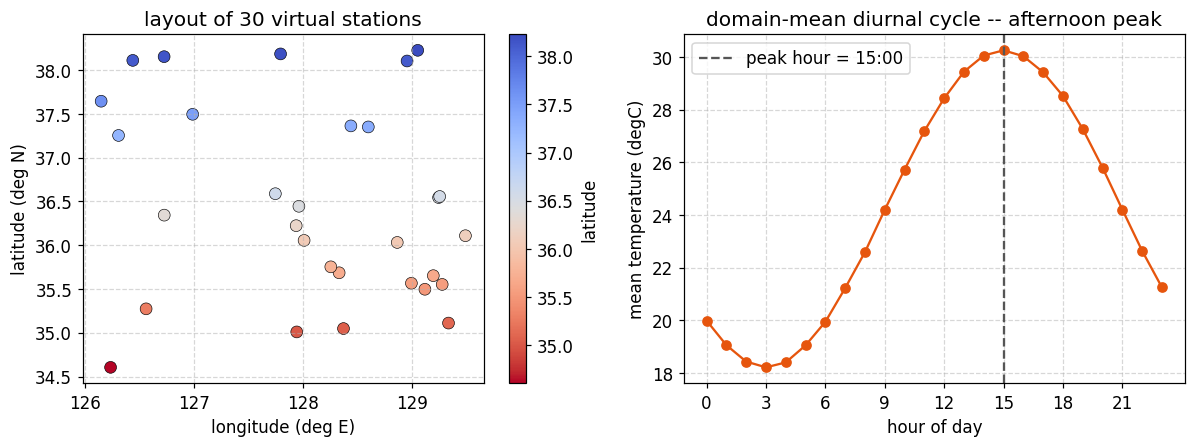

In [4]:

# Plot the station layout and the diurnal cycle we planted -- to *see* that this
# really is spatiotemporal data.
diur = obs.groupby("hour")["temp"].mean()
peak = int(diur.idxmax())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2))
sc = ax1.scatter(obs.drop_duplicates("station")["lon"],
                 obs.drop_duplicates("station")["lat"],
                 c=obs.drop_duplicates("station")["lat"], cmap="coolwarm_r",
                 s=60, edgecolor="k", linewidth=0.4)
ax1.set_xlabel("longitude (deg E)"); ax1.set_ylabel("latitude (deg N)")
ax1.set_title(f"layout of {N_STATION} virtual stations")
ax1.grid(True, ls="--", alpha=0.5)
fig.colorbar(sc, ax=ax1, label="latitude")

ax2.plot(diur.index, diur.values, "o-", color="#e6550d")
ax2.axvline(peak, ls="--", color="#555", label=f"peak hour = {peak}:00")
ax2.set_xlabel("hour of day"); ax2.set_ylabel("mean temperature (degC)")
ax2.set_title("domain-mean diurnal cycle -- afternoon peak")
ax2.set_xticks(range(0, 24, 3)); ax2.grid(True, ls="--", alpha=0.5); ax2.legend()
plt.tight_layout()
print(f"hour of maximum mean temperature: {peak}:00 (planted peak ~ 15:00)")


station 100 temperature range 14.8..35.7 degC
-> a fast diurnal cycle (period 1 day) with a slow multi-day synoptic wobble on top.
  lag features will capture the latter, hour features the former.


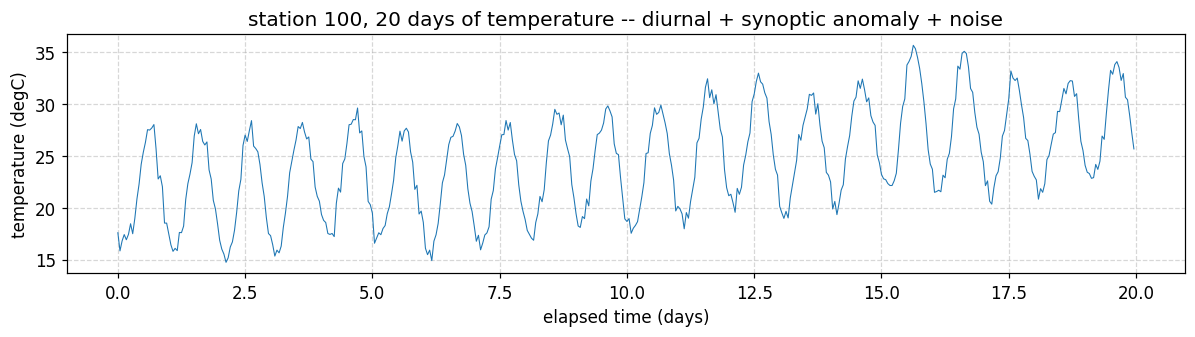

In [5]:

# The full 20-day series at one station -- the repeating diurnal cycle with a
# multi-day slow wobble (synoptic) and observation noise on top.
s0 = obs[obs["station"] == 100].sort_values("t")
fig, ax = plt.subplots(figsize=(11.0, 3.2))
ax.plot(s0["t"] / 24.0, s0["temp"], lw=0.7, color="#1f77b4")
ax.set_xlabel("elapsed time (days)"); ax.set_ylabel("temperature (degC)")
ax.set_title("station 100, 20 days of temperature -- diurnal + synoptic anomaly + noise")
ax.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
print(f"station 100 temperature range {s0['temp'].min():.1f}..{s0['temp'].max():.1f} degC")
print("-> a fast diurnal cycle (period 1 day) with a slow multi-day synoptic wobble on top.")
print("  lag features will capture the latter, hour features the former.")


> **Observe:** we built **spatiotemporal data** — 30 stations scattered over a
> wide domain (latitude 34.5–38.3°N) reporting hourly temperature. The
> domain-mean diurnal cycle reproduces exactly the **afternoon peak** (~15:00) we
> planted. On top of that sit a per-station synoptic anomaly and a satellite
> feature (vegetation), so there is genuinely **something to learn** that a single
> rule (persistence) cannot capture. Now we align these observations onto the
> grid.

---
## 2. Spatiotemporal alignment — assigning to the Week 4 grid

Forecasting and scoring happen on a **regular grid**. We assign each station to a
grid cell using the **same origin and resolution as Week 4**:

$$
g_i = \left\lfloor \frac{\text{lat} - \text{LAT0}}{\text{RES}} \right\rfloor, \qquad
g_j = \left\lfloor \frac{\text{lon} - \text{LON0}}{\text{RES}} \right\rfloor, \qquad
\text{grid\_id} = 100\,g_i + g_j
$$

with $\text{LAT0}=34,\ \text{LON0}=125.5,\ \text{RES}=0.5$ (inherited from Week 4).
Since the stations have fixed locations, the grid assignment is time-independent
and needs to be done only once.


In [6]:

LAT0, LON0, RES = 34.0, 125.5, 0.5      # same grid origin and resolution as Week 4

obs["gi"] = np.floor((obs["lat"] - LAT0) / RES).astype(int)
obs["gj"] = np.floor((obs["lon"] - LON0) / RES).astype(int)
obs["grid_id"] = obs["gi"] * 100 + obs["gj"]

n_grid = obs["grid_id"].nunique()
per_grid = obs.drop_duplicates("station").groupby("grid_id")["station"].count()
print(f"{N_STATION} stations -> {n_grid} grid cells (0.5 deg resolution)")
print(f"stations per grid cell: min {per_grid.min()}, max {per_grid.max()}, "
      f"mean {per_grid.mean():.2f}")
print("stations per grid cell (top few):")
print(per_grid.sort_values(ascending=False).head(6).to_string())


30 stations -> 25 grid cells (0.5 deg resolution)
stations per grid cell: min 1, max 2, mean 1.20
stations per grid cell (top few):
grid_id
207    2
305    2
307    2
404    2
507    2
101    1


stations in the same cell share a colour -- 25 cells in total.


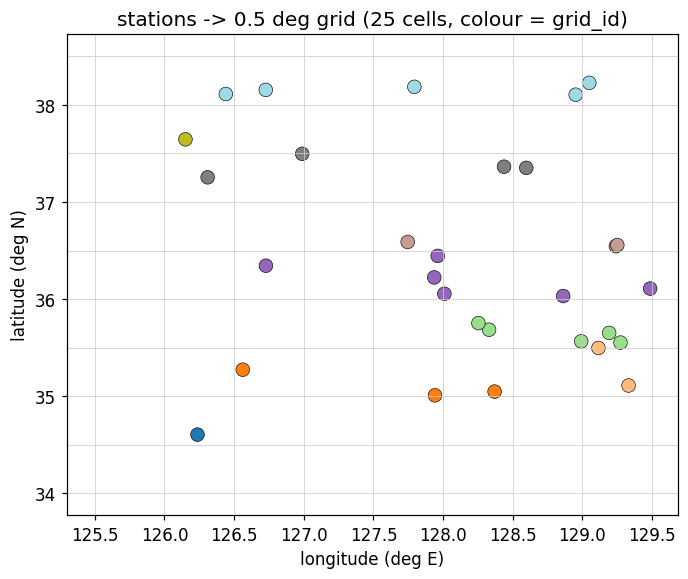

In [7]:

# Colour the stations by grid cell to see scattered observations being bundled
# onto a regular grid.
locs = obs.drop_duplicates("station")
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.scatter(locs["lon"], locs["lat"], c=locs["grid_id"], cmap="tab20",
           s=80, edgecolor="k", linewidth=0.4)
for gl in np.arange(LON0, locs["lon"].max() + RES, RES):
    ax.axvline(gl, color="#ccc", lw=0.5)
for gl in np.arange(LAT0, locs["lat"].max() + RES, RES):
    ax.axhline(gl, color="#ccc", lw=0.5)
ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg N)")
ax.set_title(f"stations -> 0.5 deg grid ({n_grid} cells, colour = grid_id)")
plt.tight_layout()
print(f"stations in the same cell share a colour -- {n_grid} cells in total.")


> **Observe:** the 30 stations were assigned to **several grid cells** by exactly
> the same rule as in Week 4. Some cells contain more than one station. With the grid
> alignment (stage ②) done, we now turn these aligned observations into a
> **supervised learning table (X, y)**.

---
## 3. Supervised framing — an (X, y) table that predicts the future from the past

The standard way to turn time-series forecasting into supervised learning is
**lag/lead**. From each station's series $T_t$:

- The **target** is the future: $y^{(L)}_{t_0} = T_{t_0 + L}$, with lead times
  $L = 1,\dots,6$.
- The **features** use only the past: $T_{t_0},\ T_{t_0-1},\ T_{t_0-3},\
  T_{t_0-24}$, and so on.

Use pandas’ groupby("station").shift(k) to get earlier or later values for each station separately:

- shift(k) gets the value k time steps earlier.
- shift(-L) gets the value L time steps later.

Always group by station before shifting. Otherwise, pandas may take a value from another station.

We start with lag0, the temperature at the forecast starting time, T_{t₀}. A persistence forecast simply uses this temperature as its prediction.

We also create the targets—the future temperatures we want to predict—and check that each input matches the correct future value.


In [8]:

obs = obs.sort_values(["station", "t"]).reset_index(drop=True)

# Targets: temperature L hours ahead (future) -- always shift inside the station.
LEADS = list(range(1, 7))
print('LEADS=',LEADS)
for L in LEADS:
    obs[f"y{L}"] = obs.groupby("station")["temp"].shift(-L)

# lag0 = the current observation = the source of persistence (past/present info).
obs["lag0"] = obs["temp"]

# Eyeball the (present, future) alignment on a few rows of one station.
demo = obs[obs["station"] == 100][["t", "hour", "temp", "lag0", "y1", "y3", "y6"]].iloc[24:30]
print("station 100 -- lag0 (= present) and the future targets y1/y3/y6 via shift(-L):")
print(demo.to_string(index=False))
print("\nCheck: a row's y1 must equal the next row's temp (one hour later).")
row = obs[obs["station"] == 100].iloc[24]
nxt = obs[obs["station"] == 100].iloc[25]
print(f"  row t={int(row['t'])} has y1={row['y1']:.3f}  vs  row t={int(nxt['t'])} has temp={nxt['temp']:.3f}")
assert abs(row["y1"] - nxt["temp"]) < 1e-9


LEADS= [1, 2, 3, 4, 5, 6]
station 100 -- lag0 (= present) and the future targets y1/y3/y6 via shift(-L):
 t  hour   temp   lag0     y1     y3     y6
24     0 17.509 17.509 16.446 16.101 17.613
25     1 16.446 16.446 15.812 15.884 18.242
26     2 15.812 15.812 16.101 17.630 20.816
27     3 16.101 16.101 15.884 17.613 22.328
28     4 15.884 15.884 17.630 18.242 23.250
29     5 17.630 17.630 17.613 20.816 24.355

Check: a row's y1 must equal the next row's temp (one hour later).
  row t=24 has y1=16.446  vs  row t=25 has temp=16.446


> **Observe:** using `groupby("station").shift(-L)` we attached the **future
> targets** $y^{(1)},\dots,y^{(6)}$ to every reference time $t_0$. We verified the
> framing by checking that a row's `y1` matches the next row's `temp` to within
> $10^{-9}$. `lag0` is the current observation — using it alone as the forecast is
> exactly **M0 persistence**. ML adds many more **past** features on top of it in
> an attempt to beat M0. We build those features next.

#### Aside: `lag0` *is* persistence — "one step back" from *which* time?

Describing persistence as "predict with the value one step back" makes it easy to
confuse with `lag1`. The confusion disappears once we separate two reference times:

- **Reference time $t_0$**: when we make the forecast = the time of the last observation
- **Target time $t_0 + L$**: the future time we are trying to predict

Persistence is the rule "**the last observed value** carries on into the future":
$\hat{T}_{t_0+L} = T_{t_0} = \texttt{lag0}$. Here "one step back" is measured from the
**target time** ($t_0$ is right before the target $t_0{+}1$ of `y1`). Lag numbers, in
contrast, count steps back from the **reference time $t_0$**.

| Feature | Value | Meaning |
|---|---|---|
| `lag0` | $T_{t_0}$ | the current (last) observation → **persistence** |
| `lag1` | $T_{t_0-1}$ | one hour earlier (an hour older than persistence) |
| `lag3` | $T_{t_0-3}$ | three hours earlier |
| `lag24` | $T_{t_0-24}$ | same hour yesterday |

At every lead time, persistence uses **the same value, `lag0`**:

| Target | Predicts | Persistence forecast | Steps before the target |
|---|---|---|---|
| `y1` | $T_{t_0+1}$ | `lag0` | 1 |
| `y3` | $T_{t_0+3}$ | `lag0` | 3 |
| `y6` | $T_{t_0+6}$ | `lag0` | 6 |

"One step back" is exactly right **only at lead 1 h**. Forecasting 6 h ahead, we do
not yet know the 5 hours in between, so the most recent usable value is `lag0` — six
steps before the target. That is why the M0 RMSE grows with lead time (Section 5).

**Connecting to AR(1)** (synoptic component only): persistence predicts
$\hat{s}_{t_0+L} = s_{t_0}$, i.e. it assumes infinite memory ($\varphi = 1$). The best
forecast is $\hat{s}_{t_0+L} = 0.92^{L}\,s_{t_0}$, which accounts for the relaxation back
to 0. At lead 1 h the two differ by only 8% of the current anomaly; at lead 6 h,
$0.92^6 \approx 0.61$, so persistence overshoots by about 39% of the current anomaly —
and the diurnal cycle has also moved a lot in 6 hours. **This is why ML (M1) has the
most room to beat persistence at long lead times.**

---
## 4. Feature engineering — lags · rolling · hour · location · satellite

To beat M0 (= `lag0` alone) we must give the model richer **past** information. We
build features along four lines:

| Line | Features | Why does it help? |
|---|---|---|
| **lag** | `lag1, lag3, lag24` | recent tendency; same hour yesterday (daily cycle) |
| **rolling** | `roll6_mean, trend6` | mean and trend over the last 6 h (rising or falling?) |
| **hour** | `hour_sin, hour_cos` | smooth encoding of the diurnal phase (afternoons are hot) |
| **location / satellite** | `lat, lon, sat_ndvi` | spatial variation (latitudinal gradient, vegetation) |

The four lines do **not** help equally. Section 7 measures, via feature
importances, which line actually carries the forecast. To give it away early: in
this data the hero at long lead times is **the hour (diurnal phase), not the
trend**.

**Banning time leakage is the crux.** Every feature must be genuinely knowable at
$t_0$: lags and rolling windows look only backwards (`shift`, `rolling`; the
future-pulling `shift(-k)` is reserved for targets), and `roll6_mean` is the mean
over $t_0{-}5 \dots t_0$. Hour, location and satellite values are known at $t_0$ by
construction.

In [9]:

gtemp = obs.groupby("station")["temp"]

# (a) lag features -- past values (positive shift)
obs["lag1"]  = gtemp.shift(1)
obs["lag3"]  = gtemp.shift(3)
obs["lag24"] = gtemp.shift(24)          # same hour, one day earlier

# (b) rolling statistics -- last 6 hours (present included, past only)
obs["roll6_mean"] = gtemp.transform(lambda s: s.rolling(6, min_periods=6).mean())
obs["trend6"]     = obs["temp"] - gtemp.shift(6)     # change over the last 6 hours (trend)

# (c) hour encoding -- diurnal phase (sin/cos makes the 24 h cycle smooth)
obs["hour_sin"] = np.sin(2 * np.pi * obs["hour"] / 24)
obs["hour_cos"] = np.cos(2 * np.pi * obs["hour"] / 24)

# (d) location and satellite columns already exist: lat, lon, sat_ndvi
FEATURES = ["lag0", "lag1", "lag3", "lag24", "roll6_mean", "trend6",
            "hour_sin", "hour_cos", "lat", "lon", "sat_ndvi"]
print(f"{len(FEATURES)} features: {FEATURES}")
print("\nsample of station 100 features (around t=30):")
print(obs[obs["station"] == 100][["t", "temp"] + FEATURES].iloc[26:29].to_string(index=False))


11 features: ['lag0', 'lag1', 'lag3', 'lag24', 'roll6_mean', 'trend6', 'hour_sin', 'hour_cos', 'lat', 'lon', 'sat_ndvi']

sample of station 100 features (around t=30):
 t   temp   lag0   lag1   lag3  lag24  roll6_mean  trend6  hour_sin  hour_cos     lat      lon  sat_ndvi
26 15.812 15.812 16.446 18.531 16.816   18.144833  -7.282  0.500000  0.866025 36.4449 127.9611     0.364
27 16.101 16.101 15.812 17.509 17.429   17.155500  -5.936  0.707107  0.707107 36.4449 127.9611     0.364
28 15.884 15.884 16.101 16.446 16.929   16.713833  -2.650  0.866025  0.500000 36.4449 127.9611     0.364


In [10]:

# Self-check for leakage: features use values up to t0 only, targets come after t0.
# Verify by hand that roll6_mean really is the 'past 6 hours including present' mean.
s = obs[obs["station"] == 100].sort_values("t").reset_index(drop=True)
i = 40
manual = s.loc[i-5:i, "temp"].mean()        # t0-5 .. t0 (6 values)
print(f"roll6_mean(t={int(s.loc[i,'t'])}) = {s.loc[i,'roll6_mean']:.4f}")
print(f"by hand  mean(temp[t0-5..t0]) = {manual:.4f}")
assert abs(s.loc[i, "roll6_mean"] - manual) < 1e-9
print("-> the rolling mean does not look into the future (past 6 h, present included).")

# trend6 = temp(t0) - temp(t0-6)
assert abs(s.loc[i, "trend6"] - (s.loc[i, "temp"] - s.loc[i-6, "temp"])) < 1e-9
print("-> trend6 also uses the past only (present minus 6 hours ago).")


roll6_mean(t=40) = 26.7410
by hand  mean(temp[t0-5..t0]) = 26.7410
-> the rolling mean does not look into the future (past 6 h, present included).
-> trend6 also uses the past only (present minus 6 hours ago).


lag0-y1 correlation 0.96 -> lag0-y6 correlation 0.29 (the persistence clue weakens as the lead time grows)


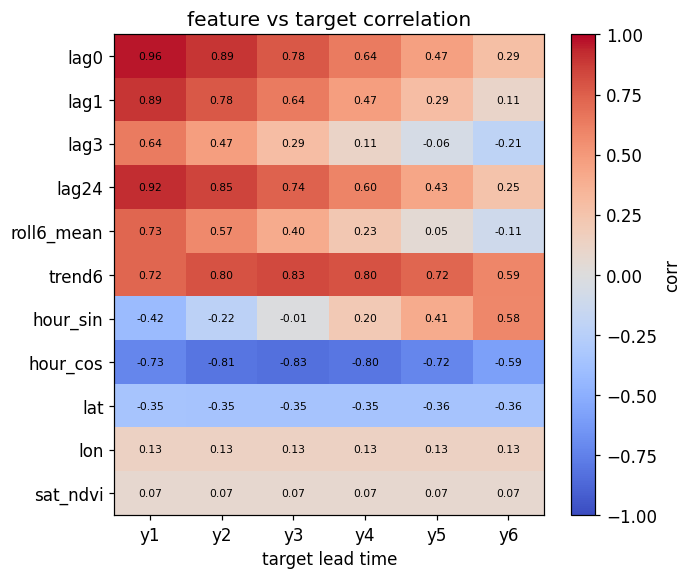

In [11]:

# How strongly is each feature related to each target? A per-lead correlation heat map,
# to build intuition -- before training -- about which feature matters at which lead.
sub = obs.dropna(subset=FEATURES + [f"y{L}" for L in LEADS])
corr = np.zeros((len(FEATURES), len(LEADS)))
for a, f in enumerate(FEATURES):
    for b, L in enumerate(LEADS):
        corr[a, b] = np.corrcoef(sub[f], sub[f"y{L}"])[0, 1]

fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(LEADS))); ax.set_xticklabels([f"y{L}" for L in LEADS])
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
ax.set_xlabel("target lead time"); ax.set_title("feature vs target correlation")
for a in range(len(FEATURES)):
    for b in range(len(LEADS)):
        ax.text(b, a, f"{corr[a,b]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="corr")
plt.tight_layout()
print(f"lag0-y1 correlation {corr[0,0]:.2f} -> lag0-y6 correlation {corr[0,5]:.2f} "
      f"(the persistence clue weakens as the lead time grows)")


> **Observe:** we built 11 features and verified by hand-computation (to within
> $10^{-9}$) that the rolling and trend features **never look into the future**.
> In the correlation heat map, the correlation between `lag0` (the current value)
> and the target **weakens** as the lead time grows from 1 to 6 — persistence's
> clue fades with distance. Features that encode the diurnal cycle, such as
> `hour_sin`/`hour_cos`, remain useful even at long leads. That difference is
> exactly why ML beats M0 by a wide margin at long lead times. Before training, one
> last discipline: the **time-based split**.

---
## 5. Time-based train/validation split + recomputing M0

**Why a time split rather than a random split?** Temperature is strongly
autocorrelated in time. If neighbouring hours of the same day are scattered
randomly across train and val, the val neighbours sit in the training set and the
model effectively **peeks at the answer** (overestimating skill). In deployment we
always **predict the future from the past**, so validation must do the same:
**train on the earlier period, validate on the later one.**

On top of that we insert a **gap**. A training sample's target reaches up to
$t_0{+}6$ into the future, so to keep those targets from overlapping the validation
period we keep only samples with **$t_0{+}6 <$ cutoff**. Then every observation
time used by training is **strictly earlier** than any validation reference time —
future leakage is impossible.

We put the cutoff at the **start of day 16** ($t = 15 \times 24 = 360$), roughly a
75% train / 25% val split.


In [12]:

# Complete samples only: rows where all features and all six targets exist.
samp = obs.dropna(subset=FEATURES + [f"y{L}" for L in LEADS]).copy()
print(f"complete supervised samples: {len(samp)} rows (first 24 h and last 6 h per station dropped)")

CUT = 15 * 24                           # =360, the start of day 16
# train: target still before the cutoff (t0+6 < CUT) -> a 6 h gap is guaranteed
train = samp[samp["t"] + 6 < CUT].copy()
# val: reference time at or after the cutoff
val = samp[samp["t"] >= CUT].copy()

print(f"train samples: {len(train)} rows  (t0 range {train['t'].min()}..{train['t'].max()})")
print(f"val   samples: {len(val)} rows  (t0 range {val['t'].min()}..{val['t'].max()})")
print(f"train fraction: {100*len(train)/(len(train)+len(val)):.0f}%")


complete supervised samples: 13500 rows (first 24 h and last 6 h per station dropped)
train samples: 9900 rows  (t0 range 24..353)
val   samples: 3420 rows  (t0 range 360..473)
train fraction: 74%


latest observation time index used by train (t0+6) : 359
earliest val reference time index (t0)             : 360
-> 359 < 360: training never sees the validation period (no leakage).


last train target 14.96 d < val start 15.00 d -> no overlap.
(note) stations are shared by both sides (30 of them) even in a time split -- we split by 'time', not by space. Only the future must stay hidden.


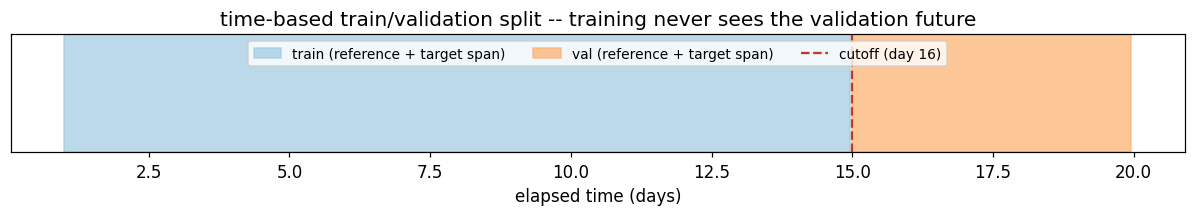

In [13]:

# Verify no future leakage: the latest observation time train 'touches' must be
# earlier than the earliest validation reference time.
train_max_obs_t = int((train["t"] + 6).max())    # latest time reached by a training target
val_min_ref_t   = int(val["t"].min())            # earliest time at which val starts predicting
print(f"latest observation time index used by train (t0+6) : {train_max_obs_t}")
print(f"earliest val reference time index (t0)             : {val_min_ref_t}")
assert train_max_obs_t < val_min_ref_t, "training must not see the future of the validation period"
print(f"-> {train_max_obs_t} < {val_min_ref_t}: training never sees the validation period (no leakage).")

# The train/val time split as a timeline -- a 6 h gap separates the future.
fig, ax = plt.subplots(figsize=(11.0, 2.1))
ax.axvspan(train["t"].min() / 24, (train["t"].max() + 6) / 24,
           color="#9ecae1", alpha=0.7, label="train (reference + target span)")
ax.axvspan(val["t"].min() / 24, (val["t"].max() + 6) / 24,
           color="#fdae6b", alpha=0.7, label="val (reference + target span)")
ax.axvline(CUT / 24, color="#c0392b", ls="--", lw=1.5, label=f"cutoff (day {CUT//24 + 1})")
ax.set_yticks([]); ax.set_xlabel("elapsed time (days)")
ax.set_title("time-based train/validation split -- training never sees the validation future")
ax.legend(loc="upper center", ncol=3, fontsize=9)
plt.tight_layout()
print(f"last train target {(train['t'].max()+6)/24:.2f} d < val start {val['t'].min()/24:.2f} d -> no overlap.")

# For contrast: with a random split, the same station's neighbouring hours would
# have landed on both sides.
overlap_stations = set(train["station"]) & set(val["station"])
print(f"(note) stations are shared by both sides ({len(overlap_stations)} of them) even in a time "
      f"split -- we split by 'time', not by space. Only the future must stay hidden.")


In [14]:

# Recompute the M0 baseline: persistence = predict 1..6 h ahead with lag0 (last obs).
def rmse(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    return float(np.sqrt(np.mean((a - b) ** 2)))

rmse_m0 = {L: rmse(val[f"y{L}"], val["lag0"]) for L in LEADS}
print("M0 (persistence) validation RMSE per lead time:")
for L in LEADS:
    print(f"  lead {L} h : {rmse_m0[L]:.3f} degC")
print(f"  mean      : {np.mean(list(rmse_m0.values())):.3f} degC")
print("-> persistence RMSE grows with lead time (the diurnal cycle drifts further away).")


M0 (persistence) validation RMSE per lead time:
  lead 1 h : 1.388 degC
  lead 2 h : 2.356 degC
  lead 3 h : 3.351 degC
  lead 4 h : 4.311 degC
  lead 5 h : 5.222 degC
  lead 6 h : 6.060 degC
  mean      : 3.781 degC
-> persistence RMSE grows with lead time (the diurnal cycle drifts further away).


> **Observe:** with a **time-based split** we separated train (earlier period) from
> val (later period), inserted a 6 h gap, and confirmed by index that training
> **never sees** the validation period (max train observation index < min val
> reference index). Recomputing the **M0 baseline** on that val set, the
> persistence RMSE **grows clearly** from lead 1 to lead 6 — that is the opponent
> we must beat. Time to train a model.

---
## 6. Training — one regressor per lead time + overfitting checks

Since the character of the prediction differs by lead time (lags matter for the
near future, the diurnal cycle for the far future), we train **one model per lead
time** (six in total). The same feature matrix $X$ is reused, only the target
$y^{(L)}$ changes. We use a **RandomForestRegressor**, which captures nonlinear
interactions well (an ensemble of trees → insensitive to feature scaling, robust
to nonlinearity and missing structure).

> **What is a random forest?** It is a crowd of **decision trees** whose answers are
> averaged.
> - **One tree** splits the data with a chain of yes/no questions — "is `hour_cos`
>   < −0.5?", "is `lag0` > 25 °C?" — until each leaf holds a handful of similar
>   samples. Its forecast is the **mean target of the training samples in that
>   leaf**. A single deep tree memorises noise.
> - **A forest** grows many trees (here `n_estimators=150`), each on a random
>   resample of the training rows and trying a random subset of features at each
>   split. The trees make different mistakes, so **averaging them cancels much of
>   the noise**.
> - Key knobs: `max_depth` (how many questions a tree may ask) and
>   `min_samples_leaf` (smallest allowed leaf) — both limit memorising.
> - Because every forecast is an average of training targets, a forest **never
>   predicts outside the range it saw in training** (no extrapolation) — we will
>   see this bite at the end of this section.

**Overfitting checks matter.** A random forest can fit the training set almost
perfectly, so its train RMSE comes out unrealistically low. The only number we
trust is the **val RMSE**. The gap between the two tells us how much we overfit;
`max_depth` and `min_samples_leaf` limit how deeply the trees can memorise.

In [15]:

Xtr = train[FEATURES].to_numpy()
Xva = val[FEATURES].to_numpy()

models = {}
rmse_tr, rmse_m1 = {}, {}
for L in LEADS:
    m = RandomForestRegressor(n_estimators=150, max_depth=14,
                              min_samples_leaf=3, random_state=0, n_jobs=-1)
    m.fit(Xtr, train[f"y{L}"].to_numpy())
    models[L] = m
    rmse_tr[L] = rmse(train[f"y{L}"], m.predict(Xtr))
    rmse_m1[L] = rmse(val[f"y{L}"], m.predict(Xva))

print(f"{'lead':>4} | {'train RMSE':>10} | {'val RMSE(M1)':>12} | {'val RMSE(M0)':>12}")
print("-" * 47)
for L in LEADS:
    print(f"{L:>4} | {rmse_tr[L]:>10.3f} | {rmse_m1[L]:>12.3f} | {rmse_m0[L]:>12.3f}")
ratio = float(np.mean([rmse_m1[L] / rmse_tr[L] for L in LEADS]))
print(f"-> val RMSE is on average {ratio:.1f}x the train RMSE: the forest partly memorises the")
print("   training set, so the train RMSE is not a fair score. Trust the val RMSE.")

lead | train RMSE | val RMSE(M1) | val RMSE(M0)
-----------------------------------------------
   1 |      0.466 |        0.924 |        1.388
   2 |      0.533 |        1.100 |        2.356
   3 |      0.580 |        1.320 |        3.351
   4 |      0.640 |        1.343 |        4.311
   5 |      0.675 |        1.481 |        5.222
   6 |      0.689 |        1.542 |        6.060
-> val RMSE is on average 2.1x the train RMSE: the forest partly memorises the
   training set, so the train RMSE is not a fair score. Trust the val RMSE.


mean train-val RMSE gap: 0.688 degC (smaller means better generalization)
-> max_depth=14 and min_samples_leaf=3 limit the memorising, yet the gap is still sizeable.


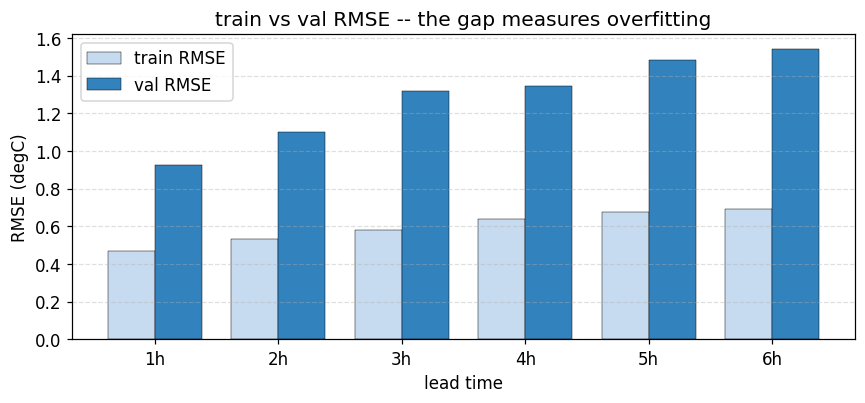

In [16]:

# Visualize overfitting: the train vs val RMSE gap per lead time.
x = np.arange(len(LEADS)); w = 0.38
fig, ax = plt.subplots(figsize=(8.0, 3.8))
ax.bar(x - w/2, [rmse_tr[L] for L in LEADS], w, label="train RMSE",
       color="#c6dbef", edgecolor="k", linewidth=0.3)
ax.bar(x + w/2, [rmse_m1[L] for L in LEADS], w, label="val RMSE",
       color="#3182bd", edgecolor="k", linewidth=0.3)
ax.set_xticks(x); ax.set_xticklabels([f"{L}h" for L in LEADS])
ax.set_xlabel("lead time"); ax.set_ylabel("RMSE (degC)")
ax.set_title("train vs val RMSE -- the gap measures overfitting")
ax.grid(True, ls="--", alpha=0.4, axis="y"); ax.legend()
plt.tight_layout()
gap = float(np.mean([rmse_m1[L] - rmse_tr[L] for L in LEADS]))
print(f"mean train-val RMSE gap: {gap:.3f} degC (smaller means better generalization)")
print("-> max_depth=14 and min_samples_leaf=3 limit the memorising, yet the gap is still sizeable.")

In [17]:

# Cross-validation on the training period (lead 3 h). Caution: shuffled KFold is a
# *random* split -- exactly what Section 5 warned against -- so neighbouring hours
# land in different folds, and every fold stays inside the training period. We run
# it to see how optimistic such a score is.
cv_model = RandomForestRegressor(n_estimators=60, max_depth=14,
                                 min_samples_leaf=3, random_state=0, n_jobs=-1)
scores = cross_val_score(cv_model, Xtr, train["y3"].to_numpy(),
                         cv=KFold(5, shuffle=True, random_state=0),
                         scoring="neg_root_mean_squared_error")
cv_rmse = -scores
print(f"lead 3 h, 5-fold CV RMSE (shuffled KFold): mean {cv_rmse.mean():.3f} +/- {cv_rmse.std():.3f} degC")
print(f"lead 3 h, time-split val RMSE            : {rmse_m1[3]:.3f} degC")
print(f"-> CV is {100 * (1 - cv_rmse.mean() / rmse_m1[3]):.0f}% lower: random folds leak neighbouring hours and")
print("   never leave the training period. The small +/- only says the folds agree with")
print("   each other, not that the score is honest. For time series use TimeSeriesSplit.")
assert cv_rmse.mean() < rmse_m1[3]

lead 3 h, 5-fold CV RMSE (shuffled KFold): mean 1.048 +/- 0.021 degC
lead 3 h, time-split val RMSE            : 1.320 degC
-> CV is 21% lower: random folds leak neighbouring hours and
   never leave the training period. The small +/- only says the folds agree with
   each other, not that the score is honest. For time series use TimeSeriesSplit.


In [18]:

# Model choice check: linear (Ridge) vs nonlinear (RandomForest), val RMSE per lead.
rmse_ridge = {}
for L in LEADS:
    r = Ridge(alpha=1.0).fit(Xtr, train[f"y{L}"].to_numpy())
    rmse_ridge[L] = rmse(val[f"y{L}"], r.predict(Xva))
print(f"{'lead':>4} | {'Ridge':>6} | {'RandomForest':>12} | {'M0':>6}")
print("-" * 38)
for L in LEADS:
    print(f"{L:>4} | {rmse_ridge[L]:>6.3f} | {rmse_m1[L]:>12.3f} | {rmse_m0[L]:>6.3f}")
n_ridge = sum(rmse_ridge[L] < rmse_m1[L] for L in LEADS)
print(f"-> Ridge beats the RandomForest at {n_ridge} of {len(LEADS)} lead times.")

# Why can the simple linear model win? A forest predicts averages of training
# targets, so it can never forecast above the training range.
ridge = Ridge(alpha=1.0).fit(Xtr, train["y3"].to_numpy())
pred_ridge3 = ridge.predict(Xva)
pred_rf3 = models[3].predict(Xva)
rmse_ridge3 = rmse_ridge[3]
print(f"\nlead 3 h  mean target : train {train['y3'].mean():.2f}  vs  val {val['y3'].mean():.2f} degC  (val is warmer)")
print(f"          max target  : train {train['y3'].max():.2f}  vs  val {val['y3'].max():.2f} degC")
print(f"          max forecast: RandomForest {pred_rf3.max():.2f}  vs  Ridge {pred_ridge3.max():.2f} degC")
print(f"          mean bias   : RandomForest {np.mean(pred_rf3 - val['y3']):+.2f}  vs  Ridge {np.mean(pred_ridge3 - val['y3']):+.2f} degC")
print("-> the forest is capped by the training range and runs cold in the warmer val period.")
print("   The data are a sum of linear terms, so a linear model that extrapolates fits them well.")
assert pred_rf3.max() <= train["y3"].max() + 1e-9
assert rmse_m1[3] < rmse_m0[3] and rmse_ridge3 < rmse_m0[3]

lead |  Ridge | RandomForest |     M0
--------------------------------------
   1 |  0.825 |        0.924 |  1.388
   2 |  0.962 |        1.100 |  2.356
   3 |  1.079 |        1.320 |  3.351
   4 |  1.179 |        1.343 |  4.311
   5 |  1.273 |        1.481 |  5.222
   6 |  1.349 |        1.542 |  6.060
-> Ridge beats the RandomForest at 6 of 6 lead times.

lead 3 h  mean target : train 23.65  vs  val 26.75 degC  (val is warmer)
          max target  : train 36.60  vs  val 38.57 degC
          max forecast: RandomForest 34.93  vs  Ridge 36.73 degC
          mean bias   : RandomForest -0.63  vs  Ridge -0.31 degC
-> the forest is capped by the training range and runs cold in the warmer val period.
   The data are a sum of linear terms, so a linear model that extrapolates fits them well.


> **Observe:** we trained **six RandomForests**, one per lead time, and the val RMSE
> we trust was **below M0 at every lead time.** Three cautions come with that result:
>
> - **The overfitting is real.** The val RMSE is about twice the train RMSE — the
>   forest partly memorises the training set.
> - **The shuffled 5-fold CV is optimistic.** Its RMSE is clearly lower than the
>   time-split val RMSE: random folds leak neighbouring hours (Section 5) and never
>   leave the training period. A small ± means the folds agree with each other, not
>   that the score is honest.
> - **A plain linear model does better.** Ridge beats the forest at every lead time.
>   The data are built as a sum of linear terms with no planted hour × location
>   interaction, and the validation period is about 3 °C warmer than training. A
>   forest can only average training targets, so it cannot forecast above the
>   training range and runs cold; Ridge extrapolates.
>
> We keep the RandomForest as M1 in this lab because it beats M0 and gives us
> feature importances to interpret in Section 7. The real lesson is that
> **validation numbers, not a model's reputation, should pick the model**: on this
> data Ridge would be the better M1 (Further Exercise 6). Next we quantify the
> improvement per lead time.

---
## 7. Evaluation — M0 vs M1 per lead time, and feature importances

The question is simply **did M1 beat M0?** We put the per-lead validation
RMSEs side by side and compute the improvement:

$$\text{improvement}(L) = 100 \times \left(1 - \frac{\text{RMSE}_{M1}(L)}{\text{RMSE}_{M0}(L)}\right)\ \%$$

First we confirm M1 < M0 at every lead time with a table and a figure, then we
interpret **what the model learned** through a predicted-vs-observed scatter plot
and the feature importances.


In [19]:

print(f"{'lead':>4} | {'M0 RMSE':>8} | {'M1 RMSE':>8} | {'impr %':>7}")
print("-" * 36)
impr = {}
for L in LEADS:
    impr[L] = 100 * (1 - rmse_m1[L] / rmse_m0[L])
    print(f"{L:>4} | {rmse_m0[L]:>8.3f} | {rmse_m1[L]:>8.3f} | {impr[L]:>6.1f}%")
mean_m0 = np.mean(list(rmse_m0.values()))
mean_m1 = np.mean(list(rmse_m1.values()))
print("-" * 36)
print(f"mean M0 {mean_m0:.3f} -> M1 {mean_m1:.3f}  "
      f"(overall improvement {100*(1-mean_m1/mean_m0):.1f}%)")

# Success condition: M1 < M0 on the mean and at every lead time.
assert mean_m1 < mean_m0, "M1 mean RMSE must be lower than M0"
assert all(rmse_m1[L] < rmse_m0[L] for L in LEADS), "M1 must win at every lead time"
print("OK: M1 beat M0 on the mean and at every lead time.")


lead |  M0 RMSE |  M1 RMSE |  impr %
------------------------------------
   1 |    1.388 |    0.924 |   33.4%
   2 |    2.356 |    1.100 |   53.3%
   3 |    3.351 |    1.320 |   60.6%
   4 |    4.311 |    1.343 |   68.8%
   5 |    5.222 |    1.481 |   71.6%
   6 |    6.060 |    1.542 |   74.6%
------------------------------------
mean M0 3.781 -> M1 1.285  (overall improvement 66.0%)
OK: M1 beat M0 on the mean and at every lead time.


the longer the lead, the larger the gain -- M1 has learned the diurnal cycle that persistence lacks.


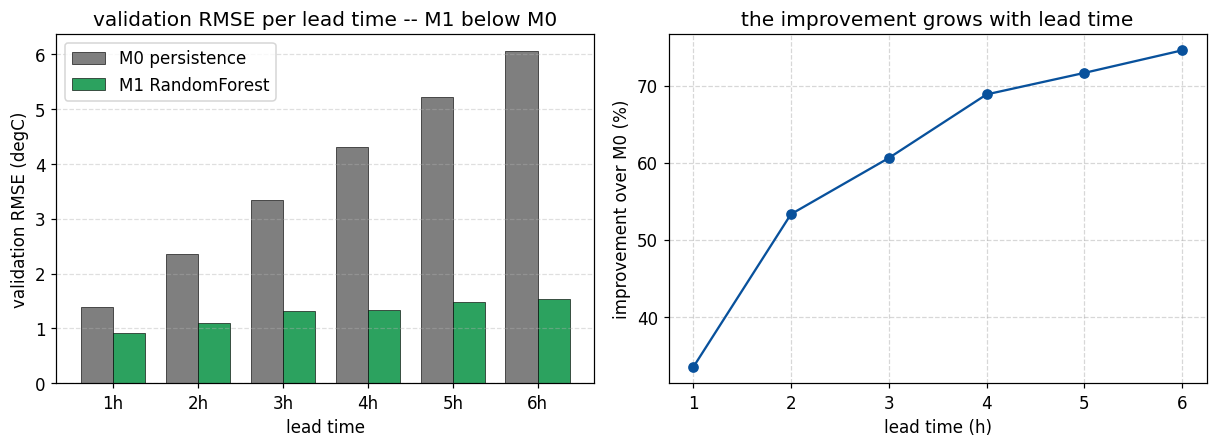

In [20]:

# Figure 1: per-lead RMSE bars -- M0 vs M1.
x = np.arange(len(LEADS)); w = 0.38
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11.2, 4.2))
axA.bar(x - w/2, [rmse_m0[L] for L in LEADS], w, label="M0 persistence",
        color="#7f7f7f", edgecolor="k", linewidth=0.4)
axA.bar(x + w/2, [rmse_m1[L] for L in LEADS], w, label="M1 RandomForest",
        color="#2ca25f", edgecolor="k", linewidth=0.4)
axA.set_xticks(x); axA.set_xticklabels([f"{L}h" for L in LEADS])
axA.set_xlabel("lead time"); axA.set_ylabel("validation RMSE (degC)")
axA.set_title("validation RMSE per lead time -- M1 below M0")
axA.grid(True, ls="--", alpha=0.4, axis="y"); axA.legend()

axB.plot(LEADS, [impr[L] for L in LEADS], "o-", color="#08519c")
axB.set_xlabel("lead time (h)"); axB.set_ylabel("improvement over M0 (%)")
axB.set_title("the improvement grows with lead time")
axB.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
print("the longer the lead, the larger the gain -- M1 has learned the diurnal cycle that persistence lacks.")


lead 6 h scatter: M0 spreads far from the diagonal (RMSE 6.06), M1 stays close (RMSE 1.54).


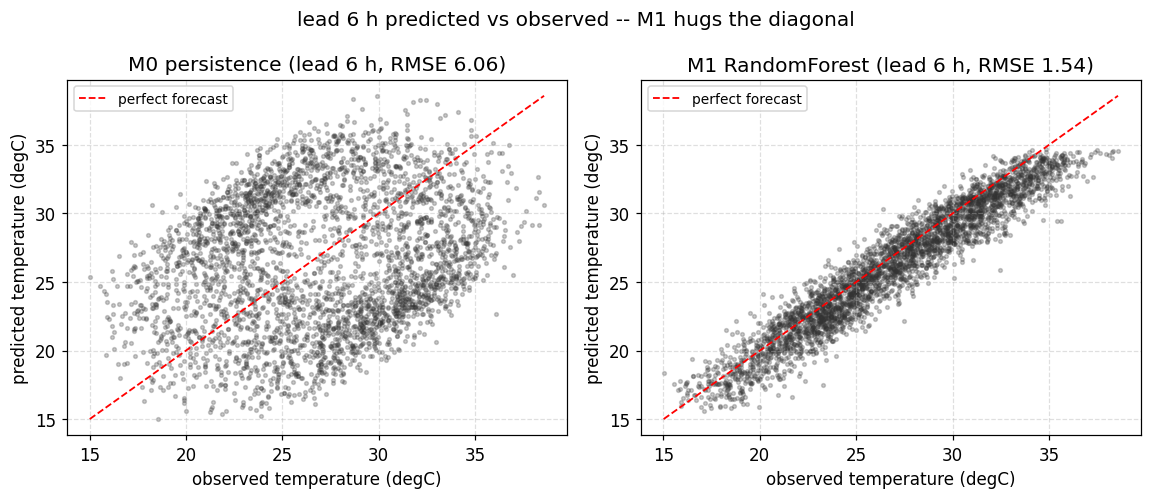

In [21]:

# Figure 2: predicted vs observed scatter (lead 6 h, validation set) -- M0 and M1 side by side.
yv = val["y6"].to_numpy()
p_m0 = val["lag0"].to_numpy()
p_m1 = models[6].predict(Xva)
lo, hi = min(yv.min(), p_m0.min()), max(yv.max(), p_m0.max())

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.6))
for ax, pred, name, rm in [(axes[0], p_m0, "M0 persistence", rmse_m0[6]),
                           (axes[1], p_m1, "M1 RandomForest", rmse_m1[6])]:
    ax.scatter(yv, pred, s=6, alpha=0.25, color="#333")
    ax.plot([lo, hi], [lo, hi], "r--", lw=1.2, label="perfect forecast")
    ax.set_xlabel("observed temperature (degC)"); ax.set_ylabel("predicted temperature (degC)")
    ax.set_title(f"{name} (lead 6 h, RMSE {rm:.2f})")
    ax.grid(True, ls="--", alpha=0.4); ax.legend(loc="upper left", fontsize=9)
fig.suptitle("lead 6 h predicted vs observed -- M1 hugs the diagonal")
plt.tight_layout()
print(f"lead 6 h scatter: M0 spreads far from the diagonal (RMSE {rmse_m0[6]:.2f}), "
      f"M1 stays close (RMSE {rmse_m1[6]:.2f}).")


residual standard deviation: M0 6.05 vs M1 1.36 degC (M1 is much narrower)


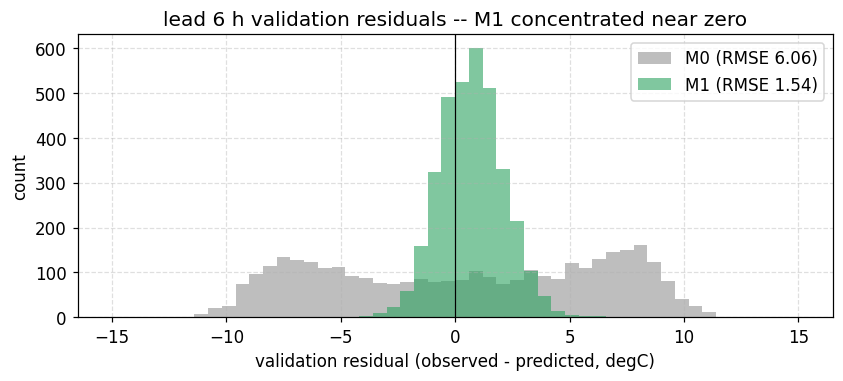

In [22]:

# Lead 6 h validation residual distribution -- M1 is more concentrated around zero.
res_m0 = yv - p_m0
res_m1 = yv - p_m1
fig, ax = plt.subplots(figsize=(7.8, 3.6))
bins = np.linspace(-15, 15, 51)
ax.hist(res_m0, bins=bins, alpha=0.5, color="#7f7f7f", label=f"M0 (RMSE {rmse_m0[6]:.2f})")
ax.hist(res_m1, bins=bins, alpha=0.6, color="#2ca25f", label=f"M1 (RMSE {rmse_m1[6]:.2f})")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("validation residual (observed - predicted, degC)"); ax.set_ylabel("count")
ax.set_title("lead 6 h validation residuals -- M1 concentrated near zero")
ax.grid(True, ls="--", alpha=0.4); ax.legend()
plt.tight_layout()
print(f"residual standard deviation: M0 {res_m0.std():.2f} vs M1 {res_m1.std():.2f} degC "
      f"(M1 is much narrower)")


top feature at lead 1 h: lag0  |  top feature at lead 6 h: hour_sin
-> near leads rely on lag (the current value); far leads are dominated by hour (diurnal phase).


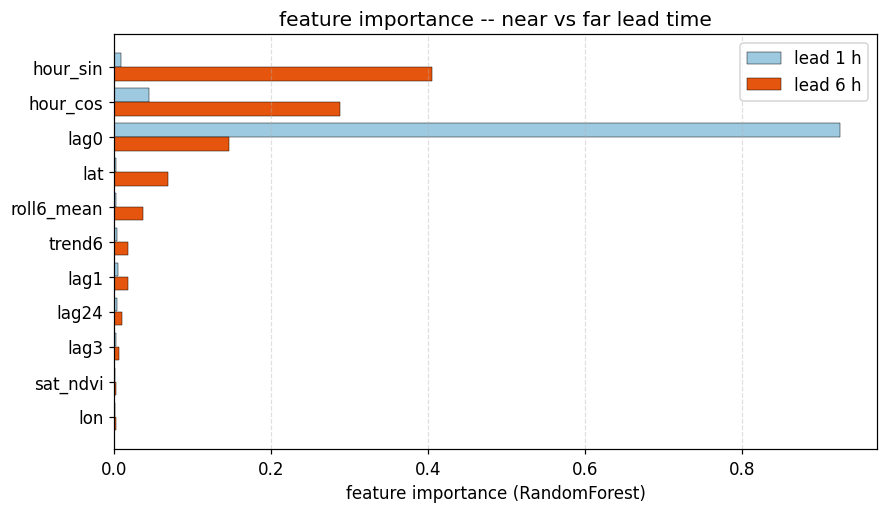

In [23]:

# Figure 3: feature importances -- how they change between a near (1 h) and far (6 h) lead.
imp1 = models[1].feature_importances_
imp6 = models[6].feature_importances_
order = np.argsort(imp6)[::-1]
feat_sorted = [FEATURES[i] for i in order]
y = np.arange(len(FEATURES))

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.barh(y - 0.2, imp1[order], 0.38, label="lead 1 h", color="#9ecae1", edgecolor="k", linewidth=0.3)
ax.barh(y + 0.2, imp6[order], 0.38, label="lead 6 h", color="#e6550d", edgecolor="k", linewidth=0.3)
ax.set_yticks(y); ax.set_yticklabels(feat_sorted)
ax.invert_yaxis()
ax.set_xlabel("feature importance (RandomForest)")
ax.set_title("feature importance -- near vs far lead time")
ax.grid(True, ls="--", alpha=0.4, axis="x"); ax.legend()
plt.tight_layout()

top1 = FEATURES[int(np.argmax(imp1))]; top6 = FEATURES[int(np.argmax(imp6))]
print(f"top feature at lead 1 h: {top1}  |  top feature at lead 6 h: {top6}")
print("-> near leads rely on lag (the current value); far leads are dominated by hour (diurnal phase).")

In [24]:
# Sum the importances by feature line -- which line carries the forecast at each lead?
GROUPS = {"lag0 (persistence)": ["lag0"],
          "lag (lag1/3/24)":    ["lag1", "lag3", "lag24"],
          "rolling roll6_mean": ["roll6_mean"],
          "trend trend6":       ["trend6"],
          "hour sin/cos":       ["hour_sin", "hour_cos"],
          "location lat/lon":   ["lat", "lon"],
          "satellite sat_ndvi": ["sat_ndvi"]}
imp_of = {1: dict(zip(FEATURES, imp1)), 6: dict(zip(FEATURES, imp6))}
print(f"{'feature line':<20} | {'lead 1 h':>8} | {'lead 6 h':>8}")
print("-" * 44)
for name, cols in GROUPS.items():
    print(f"{name:<20} | {sum(imp_of[1][c] for c in cols):>8.3f} | {sum(imp_of[6][c] for c in cols):>8.3f}")

hour6  = imp_of[6]["hour_sin"] + imp_of[6]["hour_cos"]
trend6 = imp_of[6]["trend6"]
print(f"\nlead 6 h: hour {hour6:.2f}  vs  trend6 {trend6:.3f}")
print("-> far leads are carried by the diurnal phase (hour), not by the trend.")
assert hour6 > 0.5 and trend6 < 0.05

feature line         | lead 1 h | lead 6 h
--------------------------------------------
lag0 (persistence)   |    0.925 |    0.146
lag (lag1/3/24)      |    0.011 |    0.034
rolling roll6_mean   |    0.002 |    0.036
trend trend6         |    0.003 |    0.018
hour sin/cos         |    0.053 |    0.692
location lat/lon     |    0.004 |    0.072
satellite sat_ndvi   |    0.001 |    0.003

lead 6 h: hour 0.69  vs  trend6 0.018
-> far leads are carried by the diurnal phase (hour), not by the trend.


> **Observe:** M1 **beat M0 on the mean and at every lead time**, and the gain grew
> with lead time — M1, having learned the diurnal cycle, fills in exactly where
> persistence is weakest. In the lead 6 h scatter plot M0 spreads far from the
> diagonal while M1 hugs it. The feature importances are concentrated on **`lag0`
> (the current value, about 0.9) at near leads** and move to **the hour
> (`hour_sin`+`hour_cos`, about 0.7) at far leads** — precisely what the
> correlation heat map in Section 4 predicted. Latitude (`lat`) comes next but is
> much smaller, and **the trend (`trend6`) and satellite (`sat_ndvi`) features
> contribute almost nothing.**

---
## 🔬 Exercises

The problems below extend today's framing, features and models a
little further. A working reference solution follows each one — try it yourself
first, then compare.


**Exercise 1 — why is a random split dangerous?** Train and validate a lead 1 h
model with a **random split** instead of the time split. What val RMSE do you get?
Compare it with the time-split val RMSE. Confirm that the random split gives a
**more optimistic (lower)** RMSE, and explain why that **overestimates** real
performance.


In [25]:

from sklearn.model_selection import train_test_split
Xall = samp[FEATURES].to_numpy(); yall = samp["y1"].to_numpy()
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(Xall, yall, test_size=0.25, random_state=0)
mr = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=3,
                           random_state=0, n_jobs=-1).fit(Xr_tr, yr_tr)
rmse_random = rmse(yr_va, mr.predict(Xr_va))
print(f"lead 1 h val RMSE -- random split {rmse_random:.3f}  vs  time split {rmse_m1[1]:.3f}")
print("-> the random split looks better (more optimistic): neighbouring val hours sit in train,")
print("  so the model effectively peeks at the answer. That skill does not survive deployment")
print("  (past -> future).")
assert rmse_random <= rmse_m1[1] + 1e-9


lead 1 h val RMSE -- random split 0.848  vs  time split 0.924
-> the random split looks better (more optimistic): neighbouring val hours sit in train,
  so the model effectively peeks at the answer. That skill does not survive deployment
  (past -> future).


**Exercise 2 — feature ablation.** Retrain the lead 6 h model without the hour
encoding (`hour_sin, hour_cos`). How much worse does the val RMSE get? Show
numerically how important diurnal information is at long lead times.


In [26]:

feat_no_hour = [f for f in FEATURES if f not in ("hour_sin", "hour_cos")]
m_no = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=3,
                             random_state=0, n_jobs=-1)
m_no.fit(train[feat_no_hour].to_numpy(), train["y6"].to_numpy())
rmse_no_hour = rmse(val["y6"], m_no.predict(val[feat_no_hour].to_numpy()))
print(f"lead 6 h val RMSE -- all features {rmse_m1[6]:.3f}  vs  hour removed {rmse_no_hour:.3f}")
print(f"removing the hour features degrades RMSE by {100*(rmse_no_hour/rmse_m1[6]-1):.1f}%")
print("-> at long lead times the diurnal (hour) information carries much of the predictive power.")
assert rmse_no_hour > rmse_m1[6]


lead 6 h val RMSE -- all features 1.542  vs  hour removed 3.413
removing the hour features degrades RMSE by 121.4%
-> at long lead times the diurnal (hour) information carries much of the predictive power.


**Exercise 3 — compare with GradientBoosting.** Train a
`GradientBoostingRegressor` for lead 6 h and compare its val RMSE with the
RandomForest and M0. Do both beat M0? (Check whether tree ensembles clear the
baseline reliably on this problem.)


In [27]:

from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                               random_state=0)
gb.fit(Xtr, train["y6"].to_numpy())
rmse_gb6 = rmse(val["y6"], gb.predict(Xva))
print(f"lead 6 h val RMSE -- M0 {rmse_m0[6]:.3f} | RandomForest {rmse_m1[6]:.3f} | "
      f"GradientBoosting {rmse_gb6:.3f}")
assert rmse_gb6 < rmse_m0[6]
print("-> GradientBoosting beats M0 too. Tree ensembles are reliable on these features.")


lead 6 h val RMSE -- M0 6.060 | RandomForest 1.542 | GradientBoosting 1.694
-> GradientBoosting beats M0 too. Tree ensembles are reliable on these features.


---
## Summary

Today's **pipeline practical** strung the Week 3–7 pipeline pieces together in one
notebook — **ingest → align → features → train → evaluate** — and attached the
**first data-driven forecast model** to the closed-loop twin:

- **Reframing:** spatiotemporal forecasting as supervised learning (X, y) —
  predict 1–6 h ahead from the past 24 h at each (grid cell, $t_0$).
- **Spatiotemporal alignment:** assignment to the same grid as Week 4 (LAT0=34,
  LON0=125.5, RES=0.5).
- **Feature engineering without leakage:** lags, rolling mean and trend, hour
  (sin/cos), location and satellite — with hand-computed verification that the
  rolling and trend features look only at the past.
- **Time-based split:** train (earlier) / val (later) plus a 6 h gap, with an index
  check that training never sees the validation period (contrasted with the
  optimistic bias of a random split).
- **Training:** six RandomForests, one per lead time, with overfitting checked via
  the train/val gap (val ≈ 2× train) and 5-fold CV (optimistic, being a random
  split). A plain Ridge did even better: trees cannot extrapolate into the warmer
  validation period.
- **Evaluation:** **M1 beat M0 on the mean and at every lead time**, confirmed with
  numbers and figures, with the improvement growing at longer leads. Feature
  importance: lag at near leads, hour at far leads.

> **Where are we in the pipeline?** Week 4 **aligned** observations onto the grid
> (②) and Week 5 **ingested** them (①) and produced M0; today we built the **first
> data-driven model** that forecasts the future state from those observations (the
> start of ③) and **beat M0 for the first time**. Ahead of us, Week 11 brings a
> physics simulator (M2) and Week 13 a hybrid twin that updates the state with
> observations (M3) — both trying to beat this M1, and both relying on today's
> habits of time splits, features and validation.

### Further Exercises

1. Redo the cross-validation with **TimeSeriesSplit**
   (`sklearn.model_selection.TimeSeriesSplit`). How does the RMSE differ from
   KFold? Why is it the more honest choice for time series?
2. **A unified model**: instead of six per-lead models, put `lead` in the feature
   set and predict 1–6 h with **one model**. Compare RMSE and training time against
   the six-model version.
3. Retrain without the satellite feature `sat_ndvi` and ablate how much satellite
   information contributes to predicting **spatial variation** (a preview of the
   real satellite data in Week 9).
4. **Residual analysis**: split the lead 6 h validation residuals by hour of day and
   by latitude. Where and when is M1 weakest? What does that suggest for the next
   improvement?
5. Think of ML as a **correction** to persistence: what happens if you train on the
   increment `y_L - lag0` as the target? How does that connect to Week 13's nudging
   (pushing the state toward observations)?
6. **Ridge as M1**: train Ridge for all six leads and use it as M1. When would you
   expect the RandomForest to win instead? (Hint: planted interactions such as
   hour × location, or a validation period inside the training range.)

---
We finish by reviewing today's outputs.

In [28]:

print("Pipeline practical complete. Today's outputs:")
print(f"  - supervised samples (leak-free) : train {len(train)} rows / val {len(val)} rows")
print(f"  - M0 mean validation RMSE        : {mean_m0:.3f} degC")
print(f"  - M1 mean validation RMSE        : {mean_m1:.3f} degC  "
      f"(improvement {100*(1-mean_m1/mean_m0):.1f}%)")
print("Well done -- Week 9 continues with satellite data (GEE, COG, STAC).")


Pipeline practical complete. Today's outputs:
  - supervised samples (leak-free) : train 9900 rows / val 3420 rows
  - M0 mean validation RMSE        : 3.781 degC
  - M1 mean validation RMSE        : 1.285 degC  (improvement 66.0%)
Well done -- Week 9 continues with satellite data (GEE, COG, STAC).
